# 07. Frozen-policy replay, May–September 2026

Here I apply exactly three previously fixed alert policies (calendar cap, absolute high score, constant-rate token bucket) to later Binance spot BTCUSDT one-minute data, 2026-05-01 to 2026-09-30, without tuning them on results. I refit the 2021 V+F logistic model and take the three thresholds from the spot values that notebooks 05 and 06 save, which I record in the hashed specification `FROZEN_REPLAY_SPEC.json`.

- Before any new-period result, I reproduce the 2023 to April 2026 results and the 2026 January–April alerts of notebooks 05 and 06. The May–September data come from the Binance spot archive.
- I read the spot cache that notebook 01 builds in `MyDrive/btc_lead_cost_results_77months_spot/` and write the results to `FINAL_frozen_policy_May_Sep_2026_v2_source_verified/`.
- This is a later-period frozen-policy replay, not a guaranteed untouched prospective test.


## Design

I apply exactly three previously fixed policies to later UTC data without tuning them on results: (1) Calendar Cap, (2) Absolute High Score, (3) Constant-Rate Token Bucket. I add no ODE, adaptive bucket, new signal, calibration or policy search.

My primary endpoint is the number and fraction of distinct, independently price-defined BTC crashes for which a policy emits an alert 30–240 minutes before the first 4% breach and strictly before the first 1% drawdown onset. The secondary endpoints are any pre-breach hit, realized alert count, and event-level paired comparisons.

May–September 2026 is a later-period frozen-policy replay, not a guaranteed untouched prospective test, because my earlier research viewed some prices through September 2026. I do not change the predetermined rules based on outcomes. I exclude the partial month of October so that all evaluation months are complete.

The 240-alert/year cap is an experimental constraint, not an economically justified optimum. The constant bucket has no monthly cap, so its alert count need not equal that of the calendar policies. I replay 2026 January–April before May to preserve the remaining annual quota, token balance and cooldown.

I use the spot frozen Parquet cache and the spot `price_only_event_catalog.csv` in `MyDrive/btc_lead_cost_results_77months_spot`, extended with Binance spot BTCUSDT one-minute klines from `data.binance.vision`. I never mix spot and futures data.

In [1]:
from pathlib import Path
import io, os, json, hashlib, zipfile, urllib.request, warnings, math
import numpy as np, pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from scipy.stats import binomtest
from IPython.display import display
import matplotlib.pyplot as plt
try:
    import pyarrow
except ImportError:
    import subprocess,sys
    subprocess.check_call([sys.executable,'-m','pip','-q','install','pyarrow'])
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Local execution: set BASE to a local folder with the same structure')

BASE=Path('/content/drive/MyDrive/btc_lead_cost_results_77months_spot')
# --- SPOT guard: this notebook may only read the spot cache built and fingerprint-verified by notebook 1 ---
import json as _json
_src_file = BASE/'cache'/'DATA_SOURCE.json'
if not _src_file.is_file() or _json.loads(_src_file.read_text()).get('venue') != 'spot':
    raise RuntimeError(f'Not a spot cache: {_src_file} is missing or venue!=spot. Run notebook 1 (1_..._SPOT) to completion first.')
print('SPOT cache verified:', _json.loads(_src_file.read_text())['market'])

PRICE_FILE=BASE/'cache/BTCUSDT_1m_regularized.parquet'
SIGNAL_FILE=BASE/'cache/btc_signals_1m.parquet'
OLD_EVENTS=BASE/'event_definition_eligibility_audit/price_only_event_catalog.csv'
OUT=BASE/'FINAL_frozen_policy_May_Sep_2026_v2_source_verified'
OUT.mkdir(parents=True,exist_ok=True)
for fp in [PRICE_FILE,SIGNAL_FILE,OLD_EVENTS]:
    if not fp.is_file(): raise FileNotFoundError(f'Missing frozen source: {fp}')

# Fixed dates and policies: don't change these after viewing the evaluation results.
START=pd.Timestamp('2026-05-01',tz='UTC')
END=pd.Timestamp('2026-10-01',tz='UTC')       # exclusive, five complete months
REPLAY_START=pd.Timestamp('2026-01-01',tz='UTC')
H=240; CONFIRM=5; REFRACTORY=1440
LEAD_MIN=30;LEAD_MAX=240; COOLDOWN=240
B=240; MONTH_CAP=20; BURST=20
NS=60*10**9
# Thresholds frozen by notebooks 05 and 06.
_thr_path=BASE/'FINAL_risk_adaptive_alert_capacity_v1'/'spot_frozen_thresholds.json'
_ref_path=BASE/'causal_alert_selection_v1'/'spot_reference.json'
for _p in (_thr_path,_ref_path):
    if not _p.is_file(): raise FileNotFoundError(f'Run notebooks 5 and 6 first: {_p}')
_thr=json.loads(_thr_path.read_text()); REF=json.loads(_ref_path.read_text())
assert _thr.get('venue')=='spot' and REF.get('venue')=='spot'
TH_CAL=float(_thr['TH_CAL'])
TH_HIGH=float(_thr['TH_HIGH'])
TH_BUCKET=float(_thr['TH_BUCKET'])
assert np.isclose(TH_CAL,REF['TH_CAL']) and np.isclose(TH_HIGH,REF['TH_HIGH'])
print('Spot frozen thresholds:',dict(TH_CAL=TH_CAL,TH_HIGH=TH_HIGH,TH_BUCKET=TH_BUCKET))
ALLOW_MARKET_DOWNLOAD=True
# Mandatory historical venue consistency audit.
VERIFY_MARKET_SOURCE=True
assert START==pd.Timestamp('2026-05-01',tz='UTC') and END==pd.Timestamp('2026-10-01',tz='UTC')

FROZEN_SPEC={
    'design':'later-period fixed-policy replay; exploratory overlap with earlier project possible',
    'training':'2021 V+F logistic; original historical labels',
    'historical_cache':'Binance SPOT BTCUSDT 1m (notebook-1 fingerprint verified); thresholds from spot notebooks 5-6',
    'test_start':START.isoformat(),'test_end_exclusive':END.isoformat(),
    'replay_start':REPLAY_START.isoformat(),'symbol':'BTCUSDT','source_selection':'choose Binance spot or futures/um ONLY by strict April 2026 historical-price, volume, and taker-buy-volume overlap; refuse otherwise',
    'price_event':'4% below prior 240-minute close peak; five consecutive closes; 24h refractory',
    'primary_metric':'30-240 min before first 4% breach AND before first 1% onset',
    'calendar':{'threshold':TH_CAL,'monthly_cap':20,'annual_cap':240,'cooldown_minutes':240},
    'high_score':{'threshold':TH_HIGH,'monthly_cap':20,'annual_cap':240,'cooldown_minutes':240},
    'constant_bucket':{'threshold':TH_BUCKET,'burst':20,'tokens_per_year_at_constant_rate':240,
        'annual_cap':240,'cooldown_minutes':240,'annual_reset':'UTC year'},
    'no_modifications_after_outcome_read':True,
    'not_a_never_seen_sample':True}
raw=(json.dumps(FROZEN_SPEC,ensure_ascii=False,indent=2,sort_keys=True)+'\n').encode()
spec_path=OUT/'FROZEN_REPLAY_SPEC.json'
if spec_path.exists() and spec_path.read_bytes()!=raw:
    raise RuntimeError('Previously frozen specification differs; use a new distinct study, not an overwrite.')
spec_path.write_bytes(raw)
sha=hashlib.sha256(raw).hexdigest()
(OUT/'FROZEN_REPLAY_SPEC.sha256').write_text(sha+'  FROZEN_REPLAY_SPEC.json\n')
print('Frozen study specification recorded before reading new-price outcomes. SHA-256:',sha)
print('Output folder:',OUT)

Mounted at /content/drive
SPOT cache verified: Binance spot BTCUSDT 1m klines
Spot frozen thresholds: {'TH_CAL': 0.6698990591069133, 'TH_HIGH': 0.6864782740093911, 'TH_BUCKET': 0.7166067355142407}
Frozen study specification recorded before reading new-price outcomes. SHA-256: 3b3c50393b028d5b98d4103bea51170e56f73c042bd5a69236914ad2b6d875cc
Output folder: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/FINAL_frozen_policy_May_Sep_2026_v2_source_verified


## 1. Data source

In [2]:
old_px=pd.read_parquet(PRICE_FILE).sort_index()
old_sig=pd.read_parquet(SIGNAL_FILE).sort_index()
for f in (old_px,old_sig):
    assert isinstance(f.index,pd.DatetimeIndex) and f.index.tz is not None
    f.index=f.index.tz_convert('UTC')
assert old_px.index.equals(old_sig.index), 'Historical price/signal cache indexes disagree'
assert old_px.index.is_monotonic_increasing and old_px.index.is_unique
assert (np.diff(old_px.index.asi8)==NS).all()
assert {'open','high','low','close','volume','taker_buy_vol'}.issubset(old_px.columns)
assert {'z_vol','tsr','z_hs'}.issubset(old_sig.columns)
assert old_px.index.min()<=pd.Timestamp('2021-01-01',tz='UTC')
assert old_px.index.max()>=pd.Timestamp('2026-04-30 23:59',tz='UTC')
print('Frozen cache:',old_px.index.min(),'to',old_px.index.max(),len(old_px),'rows')

RAW_COLS=['open_time','open','high','low','close','volume','close_time','quote_volume',
          'trade_count','taker_buy_vol','taker_buy_quote','ignore']

VENUE_CHOICES=('spot','futures_um')

def archive_url(month,venue):
    ym=month.strftime('%Y-%m')
    if venue=='spot': prefix='spot'
    elif venue=='futures_um': prefix='futures/um'
    else: raise ValueError('Unsupported venue: '+str(venue))
    return f'https://data.binance.vision/data/{prefix}/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-{ym}.zip'

def read_market_archive(month,venue):
    url=archive_url(month,venue)
    local=OUT/'archive_source'/venue/f'BTCUSDT-1m-{month:%Y-%m}.zip'
    local.parent.mkdir(parents=True,exist_ok=True)
    if not local.is_file():
        if not ALLOW_MARKET_DOWNLOAD:
            raise FileNotFoundError(f'Missing {local}; allow archive download')
        try:
            with urllib.request.urlopen(urllib.request.Request(url,headers={'User-Agent':'Mozilla/5.0'}),timeout=90) as h:
                content=h.read()
        except Exception as exc:
            raise RuntimeError(f'Could not download {url}. Upload matching archive into {local.parent}') from exc
        if not zipfile.is_zipfile(io.BytesIO(content)):
            raise ValueError('Archive response not a ZIP: '+url)
        local.write_bytes(content)
    with zipfile.ZipFile(local) as z:
        members=[x for x in z.namelist() if x.lower().endswith('.csv')]
        if len(members)!=1: raise ValueError(f'Expected exactly one CSV in {local}')
        with z.open(members[0]) as fd:
            x=pd.read_csv(fd,header=None,low_memory=False)
    if str(x.iloc[0,0]).strip().lower() in ('open_time','timestamp'):
        x=x.iloc[1:].reset_index(drop=True)
    if x.shape[1]!=12: raise ValueError(f'Archive schema changed: {x.shape[1]} cols; {url}')
    x.columns=RAW_COLS
    number=pd.to_numeric(x.open_time,errors='raise')
    magnitude=float(number.abs().median())
    unit=('us' if magnitude>1e14 else 'ms' if magnitude>1e11 else 's')
    if venue=='spot' and month>=pd.Timestamp('2025-01-01',tz='UTC') and unit!='us':
        warnings.warn(f'Expected microseconds from 2025 spot archives; parsed {unit}')
    time=pd.to_datetime(number,unit=unit,utc=True,errors='raise')
    z=x[['open','high','low','close','volume','taker_buy_vol']].apply(pd.to_numeric,errors='coerce')
    z.index=pd.DatetimeIndex(time,name='open_time')
    z=z[~z.index.duplicated(keep='last')].sort_index()
    assert z.index.min().year==month.year and z.index.min().month==month.month
    return z.astype('float64'),hashlib.sha256(local.read_bytes()).hexdigest()

def compare_april(archived,venue,sha):
    join=archived.index.intersection(old_px.index)
    if len(join)<1000:
        return [{'venue':venue,'column':c,'aligned_rows':len(join), 'fraction_strict_match':0.,
            'median_absolute_difference':float('nan'),'p95_absolute_difference':float('nan'),
            'archive_sha256':sha,'first_cache':float('nan'), 'first_archive':float('nan')}
            for c in ('close','volume','taker_buy_vol')]
    # ~1,000 evenly-spaced aligned rows, spanning the whole historical overlap month
    sam=join[::max(1,len(join)//1000)]
    output=[]
    for col in ['close','volume','taker_buy_vol']:
        x=old_px.loc[sam,col].to_numpy(float)
        y=archived.loc[sam,col].to_numpy(float)
        strict=np.isclose(x,y,rtol=2e-8,atol=1e-7,equal_nan=True)
        valid=np.isfinite(x)&np.isfinite(y)
        diff=np.abs(x[valid]-y[valid])
        output.append({'venue':venue,'column':col,'aligned_rows':len(join),
            'sample_rows':len(sam),'fraction_strict_match':float(strict.mean()),
            'median_absolute_difference':float(np.median(diff)) if len(diff) else float('nan'),
            'p95_absolute_difference':float(np.percentile(diff,95)) if len(diff) else float('nan'),
            'archive_sha256':sha,'first_cache':float(x[0]),'first_archive':float(y[0])})
    return output

# Historical-venue selection is performed before touching new evaluation data.
source_log=[]
APRIL=pd.Timestamp('2026-04-01',tz='UTC')
comparison_rows=[];archives={};archive_errors=[]
if not VERIFY_MARKET_SOURCE: raise RuntimeError('Venue verification has to stay enabled')
for venue in VENUE_CHOICES:
    try:
        april,hash_apr=read_market_archive(APRIL,venue)
        archives[venue]=(april,hash_apr)
        comparison_rows.extend(compare_april(april,venue,hash_apr))
    except Exception as ex:
        archive_errors.append(f'{venue}: {type(ex).__name__}: {ex}')
comparison_df=pd.DataFrame(comparison_rows)
if not comparison_df.empty:
    comparison_df.to_csv(OUT/'AUDIT_april_2026_market_overlap.csv',index=False)
    display(comparison_df.drop(columns=['archive_sha256']))
matching=[]
for venue in VENUE_CHOICES:
    row=comparison_df.loc[comparison_df.venue.eq(venue)] if not comparison_df.empty else pd.DataFrame()
    if len(row)==3 and (row.fraction_strict_match==1).all() and (row.aligned_rows>=1000).all():
        matching.append(venue)
if len(matching)!=1:
    raise RuntimeError(
        'Historical price cache did not uniquely match a published Binance venue. '
        f'Strict matching markets: {matching}. Archive errors: {archive_errors}. '
        f'Read {OUT/"AUDIT_april_2026_market_overlap.csv"} and locate the actual original 1m source. '
        'Different venues cannot be combined, and the guard stays enabled; the three policy thresholds do not transfer across venues.')
SELECTED_VENUE=matching[0]
if SELECTED_VENUE!='spot':
    raise RuntimeError(f'This is the spot notebook, but the cache matched the {SELECTED_VENUE} archive. Check the notebook 1 cache.')
april,hash_apr=archives[SELECTED_VENUE]
source_log.append({'month':'2026-04 overlap verification','venue':SELECTED_VENUE,
    'source':archive_url(APRIL,SELECTED_VENUE), 'sha256':hash_apr,'rows':len(april)})
print('Historical venue exact-overlap PASS:',SELECTED_VENUE)
# If the cache does not reach the last requested month, download only missing calendar months.
needed=pd.date_range(START,END,freq='MS',inclusive='left')
missing=[m for m in needed if old_px.index.max()<m+pd.offsets.MonthBegin(1)-pd.Timedelta(minutes=1)]
print('Months requiring download:',[str(m)[:7] for m in missing])
parts=[old_px]
for month in missing:
    block,hashzip=read_market_archive(month,SELECTED_VENUE)
    parts.append(block)
    source_log.append({'month':str(month)[:7],'venue':SELECTED_VENUE,'source':archive_url(month,SELECTED_VENUE),'sha256':hashzip,'rows':len(block)})
    print('Loaded:',str(month)[:7],len(block))
all_px=pd.concat(parts).sort_index()
all_px=all_px[~all_px.index.duplicated(keep='first')]
# Short-gap convention of notebook 1: a <=5min missing run uses ffilled OHLC and zero trade volume.
regular_idx=pd.date_range(all_px.index.min(),END-pd.Timedelta(minutes=1),freq='min',tz='UTC')
all_px=all_px.reindex(regular_idx)
raw_missing=all_px['close'].isna().to_numpy()
if raw_missing.any():
    boundary=np.r_[True,raw_missing[1:]!=raw_missing[:-1]]
    runid=np.cumsum(boundary)-1
    counts=np.bincount(runid[raw_missing],minlength=int(runid.max()+1))
    short=raw_missing & (counts[runid]<=5)
    for col in ['open','high','low','close']:
        z=all_px[col].ffill().to_numpy();all_px.loc[short,col]=z[short]
    for col in ['volume','taker_buy_vol']:all_px.loc[short,col]=0.
    print('Missing minutes:',int(raw_missing.sum()),'short-fill:',int(short.sum()),
          'long-gap preserved:',int((raw_missing&~short).sum()))
assert all_px.index[-1]==END-pd.Timedelta(minutes=1)
assert len(all_px.loc[START:END-pd.Timedelta(minutes=1)])==len(pd.date_range(START,END,freq='min',inclusive='left'))
pd.DataFrame(source_log).to_csv(OUT/'source_archive_manifest.csv',index=False)
print('Extended full bar history:',all_px.index[0],all_px.index[-1])

Frozen cache: 2020-01-01 00:00:00+00:00 to 2026-04-30 23:59:00+00:00 3329280 rows


,venue,column,aligned_rows,sample_rows,fraction_strict_match,median_absolute_difference,p95_absolute_difference,first_cache,first_archive
0,spot,close,43200,1005,1.0,0.00000,0.000000,68218.35000,68218.35000
1,spot,volume,43200,1005,1.0,0.00000,0.000000,14.75370,14.75370
2,spot,taker_buy_vol,43200,1005,1.0,0.00000,0.000000,6.20199,6.20199
3,futures_um,close,43200,1005,0.0,38.34000,49.582000,68218.35000,68171.00000
4,futures_um,volume,43200,1005,0.0,43.91520,319.971248,14.75370,118.23500
5,futures_um,taker_buy_vol,43200,1005,0.0,21.27198,167.729728,6.20199,28.44800


Historical venue exact-overlap PASS: spot
Months requiring download: ['2026-05', '2026-06', '2026-07', '2026-08', '2026-09']
Loaded: 2026-05 44640
Loaded: 2026-06 43200
Loaded: 2026-07 44640
Loaded: 2026-08 44640
Loaded: 2026-09 43200
Missing minutes: 2325 short-fill: 0 long-gap preserved: 2325
Extended full bar history: 2020-01-01 00:00:00+00:00 2026-09-30 23:59:00+00:00


## 2. Extend the V/F/H validity features (no new model)

`z_vol` uses 32-minute realized volatility plus the trailing 30-day *past-only* log-volatility mean and standard deviation; `tsr` is `1 - taker_buy_vol / volume`. I compute `z_hs` only so that the candidate validity mask matches the frozen pipeline; the predictor itself uses V and F only.

In [3]:
from numpy.lib.stride_tricks import sliding_window_view
# Recreate features on a local trailing region (60 days pre May + the new period).
# A 30-day rolling normalization requires >=30 days of prior data for exact overlap checks.
feat_begin=START-pd.Timedelta(days=60)
tail=all_px.loc[feat_begin:END-pd.Timedelta(minutes=1)].copy()
close=tail.close
r=np.log(close).diff()
volatility=r.rolling(31,min_periods=31).std()
lrv=np.log(volatility.where(volatility>0))
baseline=lrv.rolling(30*1440,min_periods=15*1440)
zv=(lrv-baseline.mean().shift(1))/baseline.std().shift(1).replace(0,np.nan)
ts=((tail.volume-tail.taker_buy_vol)/tail.volume.replace(0,np.nan)).clip(0,1)

# hS is used solely to replicate the cached common-data validity mask.
p32=close.to_numpy(dtype=np.float32)
hs=np.full(len(p32),np.nan,dtype=np.float64)
for start in range(31,len(p32),90_000):
    end=min(len(p32),start+90_000)
    window=sliding_window_view(p32[start-31:end],32)
    centered=window-window.mean(axis=1,keepdims=True)
    hs[start:end]=np.abs(np.fft.rfft(centered,axis=1))[:,-8:].mean(axis=1)
log_hs=pd.Series(np.log1p(hs),index=tail.index)
hbaseline=log_hs.rolling(30*1440,min_periods=15*1440)
zh=(log_hs-hbaseline.mean().shift(1))/hbaseline.std().shift(1).replace(0,np.nan)
new_features=pd.DataFrame({'z_vol':zv.astype('float32'),'tsr':ts.astype('float32'),
                           'z_hs':zh.astype('float32')},index=tail.index)
# Guard that the reconstructed features match the cached 2026-April values.
overlap=old_sig.index.intersection(new_features.index)
overlap=overlap[(overlap>=pd.Timestamp('2026-04-20',tz='UTC'))&
                (overlap<pd.Timestamp('2026-05-01',tz='UTC'))]
assert len(overlap)>5_000, 'Need a >5000-minute cached overlap for the feature test'
for col,absolute_tol in [('z_vol',5e-4),('tsr',5e-6),('z_hs',5e-4)]:
    x=old_sig.loc[overlap,col].to_numpy(float)
    ynew=new_features.loc[overlap,col].to_numpy(float)
    usable=np.isfinite(x)&np.isfinite(ynew)
    assert usable.sum()>4_000, 'Too few comparable overlap features: '+col
    maxdiff=float(np.max(np.abs(x[usable]-ynew[usable])))
    print('Cached vs reconstructed feature',col,'max abs diff:',maxdiff)
    if maxdiff>absolute_tol:
        raise RuntimeError(f'{col} historical overlap mismatch {maxdiff:.6g} > {absolute_tol}; the features cannot be combined.')

# Reuse cached historical feature values unchanged. Only absent minutes get reconstructed features.
features=pd.concat([old_sig[['z_vol','tsr','z_hs']],
                    new_features.loc[new_features.index.difference(old_sig.index)]],axis=0).sort_index()
features=features.reindex(all_px.index)
assert features.index.equals(all_px.index)
valid=(np.isfinite(all_px.close.to_numpy(float))&(all_px.close.to_numpy(float)>0)&
       (all_px.volume.to_numpy(float)>0)&np.isfinite(features.z_vol.to_numpy(float))&
       np.isfinite(features.tsr.to_numpy(float))&np.isfinite(features.z_hs.to_numpy(float))&
       (features.tsr.to_numpy(float)>=0)&(features.tsr.to_numpy(float)<=1))
print('New valid 1m score rows:',int(valid[all_px.index>=START].sum()))
if valid[(all_px.index>=START)&(all_px.index<END)].mean()<0.95:
    raise RuntimeError('Less than 95% post-May bars have complete features: investigate source/data gaps')

Cached vs reconstructed feature z_vol max abs diff: 0.0
Cached vs reconstructed feature tsr max abs diff: 0.0
Cached vs reconstructed feature z_hs max abs diff: 1.1920928955078125e-07
New valid 1m score rows: 220320


## 3. Rebuild the same price-only event catalog independently

A new event is the first 4% drawdown below the **preceding** 240-minute peak, sustained for five one-minute closes below its fixed threshold; another event requires 24 hours after the **previous confirmation** and a fresh peak. The breach, not the confirmation, is the warning deadline. I use this catalog only to construct outcomes, never as an input to the policies.

In [4]:
def price_only_catalog(close,volume,index,H=240,decline=.04,sustain=5,refractory=1440):
    c=np.asarray(close,dtype=np.float64)
    obs=np.isfinite(c)&(c>0)&np.isfinite(volume)&(np.asarray(volume)>0)
    prior=pd.Series(np.where(obs,c,np.nan)).rolling(H,min_periods=H).max().shift(1).to_numpy()
    raw=obs & np.isfinite(prior) & (c<=(1-decline)*prior)
    fresh=raw & ~np.r_[False,raw[:-1]]
    rows=[];last_confirm=-10**12
    for i in np.flatnonzero(fresh):
        if i+sustain>len(c) or i-last_confirm<refractory:continue
        threshold=(1-decline)*prior[i]
        if not(obs[i:i+sustain].all() and np.all(c[i:i+sustain]<=threshold)):continue
        if i-H<0 or not obs[i-H:i].all():continue
        prev=c[i-H:i];peak_i=int(i-H+np.argmax(prev))
        if peak_i<=last_confirm:continue
        onset_candidates=np.flatnonzero(c[peak_i+1:i+1]<=.99*c[peak_i])
        if not len(onset_candidates):continue
        oi=int(peak_i+1+onset_candidates[0])
        rows.append({'event_id':len(rows)+1,'peak_utc':index[peak_i],
                     'onset_1pct_utc':index[oi], 'breach_utc':index[i],
                     'confirmed_utc':index[i+sustain-1],
                     'peak_close':float(c[peak_i]),'breach_close':float(c[i]),
                     'decline_at_breach_pct':(c[i]/c[peak_i]-1)*100,
                     'peak_to_breach_minutes':i-peak_i,
                     'onset_to_breach_minutes':i-oi})
        last_confirm=i+sustain-1
    df=pd.DataFrame(rows)
    if not len(df):raise RuntimeError('No price-only crash events generated; inspect price history')
    df['year']=pd.DatetimeIndex(df.breach_utc).year
    return df

catalog=price_only_catalog(all_px.close.to_numpy(float),all_px.volume.to_numpy(float),all_px.index)
old_events=pd.read_csv(OLD_EVENTS)
for col in ['peak_utc','onset_1pct_utc','breach_utc','confirmed_utc']:
    old_events[col]=pd.to_datetime(old_events[col],utc=True)
    catalog[col]=pd.to_datetime(catalog[col],utc=True)
old_replay=catalog[catalog.breach_utc<START].reset_index(drop=True)
ref=old_events[old_events.breach_utc<START].reset_index(drop=True)
assert len(old_replay)==len(ref),f'Cached catalog count changed: recomputed={len(old_replay)},cached={len(ref)}'
for col in ['peak_utc','onset_1pct_utc','breach_utc','confirmed_utc']:
    assert old_replay[col].equals(ref[col]),'Frozen event definition not reproduced: '+col
assert (ref[(ref.breach_utc>=pd.Timestamp('2023-01-01 04:00',tz='UTC'))].shape[0]==REF['n_primary_events']), 'Spot primary-period event count changed vs notebook 5'
# 4-hour event-window warmup exclusion: no event relies on alert eligible only before May 1.
EVAL_START=START+pd.Timedelta(minutes=LEAD_MAX)
NEW_EVENTS=catalog[(catalog.breach_utc>=EVAL_START)&(catalog.breach_utc<END)].reset_index(drop=True)
if NEW_EVENTS.empty: print('No new qualifying 4% crashes in the five-month sample; recall is zero or undefined.')
NEW_EVENTS.to_csv(OUT/'later_period_price_only_events.csv',index=False)
print('Frozen events through Apr reproduced:',len(ref),'| New events after 4h warmup:',len(NEW_EVENTS))
display(NEW_EVENTS[['event_id','onset_1pct_utc','breach_utc','confirmed_utc']].head(15))

Frozen events through Apr reproduced: 269 | New events after 4h warmup: 2


,event_id,onset_1pct_utc,breach_utc,confirmed_utc
0,270,2026-06-03 22:21:00+00:00,2026-06-04 01:14:00+00:00,2026-06-04 01:18:00+00:00
1,271,2026-06-24 13:03:00+00:00,2026-06-24 15:44:00+00:00,2026-06-24 15:48:00+00:00


## 4. Refit the frozen 2021 estimator and apply three locked thresholds

I take labels from the 2021 price-only events only. The model pipeline is `StandardScaler + LogisticRegression(C=.2, class_weight='balanced', solver='lbfgs', random_state=17)`. I do no fitting, threshold search or model selection on May–September data.

In [5]:
T=all_px.index.asi8
bns=old_events.breach_utc.astype('int64').to_numpy()
idx_next=np.searchsorted(bns,T+LEAD_MIN*NS,side='left')
y=np.zeros(len(T),dtype=np.int8)
ok=idx_next<len(bns)
y[ok]=(bns[idx_next[ok]]<=T[ok]+LEAD_MAX*NS).astype(np.int8)
train=valid&(T>=pd.Timestamp('2021-01-01',tz='UTC').value)&(T<pd.Timestamp('2022-01-01',tz='UTC').value-(LEAD_MAX+5)*NS)
assert train.sum()>100_000 and 0<y[train].sum()<train.sum()
X=np.column_stack([features.z_vol.to_numpy(float),features.tsr.to_numpy(float)])
clf=make_pipeline(StandardScaler(),LogisticRegression(C=.2,class_weight='balanced',
                        max_iter=400,solver='lbfgs',random_state=17))
clf.fit(X[train],y[train])
S=np.full(len(T),np.nan,float)
S[valid]=clf.predict_proba(X[valid])[:,1]
print('Model refit done: training minutes',int(train.sum()),'positive labels',int(y[train].sum()))

Model refit done: training minutes 524087 positive labels 18779


## 5. Frozen online schedulers and the January–April state

I replay **all of 2026 from January 1** and score events only from May 1 04:00 to September 30. This preserves the token bucket's remaining tokens, the annual alert count, the cooldown and the calendar monthly resets. The bucket starts each UTC year at 20 tokens and refills continuously at 240/365.2425/1440 tokens per minute, with no monthly limit. No policy uses future scores or event labels.

In [6]:
def emit_calendar(t,s,threshold,B=240,cap=20,cooldown=240):
    t=np.asarray(t,np.int64);s=np.asarray(s,float)
    assert len(t)==len(s) and (len(t)<2 or np.all(np.diff(t)>0))
    candidates=np.flatnonzero(np.isfinite(s)&(s>=threshold))
    out=[];last=-(10**25);annual=0;monthly=0;py=None;pm=None
    for i in candidates:
        ti=int(t[i]);dt=pd.Timestamp(ti,tz='UTC');year=int(dt.year);mon=year*12+int(dt.month)
        if year!=py:annual=0;py=year
        if mon!=pm:monthly=0;pm=mon
        if annual>=B or monthly>=cap or ti-last<cooldown*NS:continue
        out.append(ti);annual+=1;monthly+=1;last=ti
    return np.asarray(out,dtype=np.int64)

def emit_constant_bucket(t,s,threshold,B=240,burst=20,cooldown=240):
    t=np.asarray(t,np.int64);s=np.asarray(s,float)
    assert len(t)==len(s) and (len(t)<2 or np.all(np.diff(t)>0))
    candidates=np.flatnonzero(np.isfinite(s)&(s>=threshold))
    out=[];py=None;annual=0;tokens=float(burst);last_t=None;last_alert=-(10**25)
    for i in candidates:
        ti=int(t[i]);year=int(pd.Timestamp(ti,tz='UTC').year)
        if year!=py:
            py=year;annual=0;tokens=float(burst);last_t=ti
        if last_t is not None and ti>last_t:
            tokens=min(float(burst),tokens+(ti-last_t)/NS*B/(365.2425*1440))
        last_t=ti
        if annual>=B or tokens<1-1e-9 or ti-last_alert<cooldown*NS:continue
        out.append(ti);tokens=max(0,tokens-1);annual+=1;last_alert=ti
    return np.asarray(out,dtype=np.int64)

def match_events(events,alerts):
    a=np.sort(np.asarray(alerts,np.int64));used=set();rows=[]
    for ev in events.itertuples(index=False):
        b=ev.breach_utc.value;o=ev.onset_1pct_utc.value
        l=int(np.searchsorted(a,b-LEAD_MAX*NS,'left'))
        r=int(np.searchsorted(a,b-LEAD_MIN*NS,'right'))
        for j in range(l,r):
            if j in used:continue
            used.add(j)
            rows.append({'event_id':int(ev.event_id),'breach_utc':ev.breach_utc,
                         'alarm_utc':pd.Timestamp(int(a[j]),tz='UTC'),
                         'lead_min':(b-int(a[j]))/NS,'pre1pct':bool(a[j]<o)})
            break
    return pd.DataFrame(rows,columns=['event_id','breach_utc','alarm_utc','lead_min','pre1pct'])

# Synthetic tests for monthly caps, cooldown and state continuity.
_t=pd.date_range('2026-01-01',periods=150*24,freq='h',tz='UTC').asi8
_sc=np.ones(len(_t))
_a=emit_calendar(_t,_sc,.5)
assert all(pd.Series(pd.to_datetime(_a,utc=True)).dt.to_period('M').value_counts()<=20)
assert len(_a)==100 and np.all(np.diff(_a)>=240*NS)
_b=emit_constant_bucket(_t,_sc,.5)
assert np.all(np.diff(_b)>=240*NS)
assert len(_b)<=240
assert len(_b)==len(emit_constant_bucket(_t,_sc,.5))
assert np.array_equal(_b[_b>=pd.Timestamp('2026-05-01',tz='UTC').value],
    emit_constant_bucket(_t,_sc,.5)[emit_constant_bucket(_t,_sc,.5)>=pd.Timestamp('2026-05-01',tz='UTC').value])
print('Online scheduler synthetic checks PASS')

Online scheduler synthetic checks PASS


/tmp/ipykernel_883/2081905361.py:49: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  assert all(pd.Series(pd.to_datetime(_a,utc=True)).dt.to_period('M').value_counts()<=20)


## 6. Historical reproduction before new-period results

Before I look at any new-period result, I reproduce the spot calendar and high-score results that notebook 05 saves for 2023 to April 2026 (`spot_reference.json`) and the 2026 January–April alerts that notebooks 05 and 06 emit for all three policies.

In [7]:
HIST_START=pd.Timestamp('2023-01-01',tz='UTC')
HIST_END=pd.Timestamp('2026-05-01',tz='UTC')
oldmask=(all_px.index>=HIST_START)&(all_px.index<HIST_END)
h_t=T[oldmask];h_s=S[oldmask]
h_events=catalog[(catalog.breach_utc>=HIST_START+pd.Timedelta(minutes=LEAD_MAX))&
                 (catalog.breach_utc<HIST_END)].copy()
assert len(h_events)==REF['n_primary_events']
hist_summary={}
for name,th in [('calendar',TH_CAL),('high_score',TH_HIGH)]:
    a=emit_calendar(h_t,h_s,th)
    m=match_events(h_events,a)
    hist_summary[name]=(len(a),len(m),int(m.pre1pct.sum()))
assert list(hist_summary['calendar'])==REF['first_eligible'],f"Frozen Calendar mismatch: {hist_summary} vs {REF['first_eligible']}"
assert list(hist_summary['high_score'])==REF['absolute_high_score'],f"Frozen High Score mismatch: {hist_summary} vs {REF['absolute_high_score']}"
print('Historical reproduction PASS:',hist_summary)

REPLAY_END=END
mask=(all_px.index>=REPLAY_START)&(all_px.index<REPLAY_END)
r_t=T[mask];r_s=S[mask]
ALL_ALERTS={
  'calendar':emit_calendar(r_t,r_s,TH_CAL),
  'high_score':emit_calendar(r_t,r_s,TH_HIGH),
  'constant_bucket':emit_constant_bucket(r_t,r_s,TH_BUCKET)
}
old_2026=catalog[(catalog.breach_utc>=pd.Timestamp('2026-01-01 04:00',tz='UTC'))&
                 (catalog.breach_utc<pd.Timestamp('2026-05-01',tz='UTC'))]
# Expected 2026 Jan–Apr state comes from the alerts that spot notebooks 5 and 6 emitted.
_REF_ALARMS={'calendar':BASE/'causal_alert_selection_v1'/'alarms_first_eligible.csv',
             'high_score':BASE/'causal_alert_selection_v1'/'alarms_absolute_high_score.csv',
             'constant_bucket':BASE/'FINAL_risk_adaptive_alert_capacity_v1'/'alarms_constant_bucket_recalibrated.csv'}
prior_expected={};_carry={}
for _name,_path in _REF_ALARMS.items():
    if not _path.is_file(): raise FileNotFoundError(f'Alert file from notebooks 5-6 not found: {_path}')
    _a=pd.to_datetime(pd.read_csv(_path)['alarm_utc'],utc=True).astype('int64').to_numpy()
    _a26=_a[(_a>=REPLAY_START.value)&(_a<HIST_END.value)]
    _h=match_events(old_2026,_a26)
    prior_expected[_name]=(len(_a26),len(_h),int(_h.pre1pct.sum()))
    _carry[_name]=bool(((_a>=REPLAY_START.value-COOLDOWN*NS)&(_a<REPLAY_START.value)).any())
print('Spot 2026 Jan–Apr reference from notebooks 5–6:',prior_expected)
for name,a in ALL_ALERTS.items():
    old_a=a[a<HIST_END.value]
    hit=match_events(old_2026,old_a)
    res=(len(old_a),len(hit),int(hit.pre1pct.sum()))
    if res!=prior_expected[name]:
        if _carry[name]:
            # The long-run notebooks carry the 240-min cooldown across 2025-12-31 → 2026-01-01; this replay starts fresh on 1 January.
            warnings.warn(f'{name}: 2026 Jan-Apr {res} vs reference {prior_expected[name]} differs only because of the year-boundary cooldown carry-over. Report this.')
            print('Warning:', name, res, 'vs', prior_expected[name], '(year-boundary cooldown carry-over)')
            continue
        raise AssertionError(f'{name} 2026 Jan-Apr state mismatch: {res} vs {prior_expected[name]}; the new comparison is not valid.')
    print(name,'2026 Jan-Apr replay PASS:',res)

Historical reproduction PASS: {'calendar': (800, 39, 22), 'high_score': (800, 41, 19)}
Spot 2026 Jan–Apr reference from notebooks 5–6: {'calendar': (80, 3, 3), 'high_score': (80, 3, 3), 'constant_bucket': (75, 4, 2)}
calendar 2026 Jan-Apr replay PASS: (80, 3, 3)
high_score 2026 Jan-Apr replay PASS: (80, 3, 3)
constant_bucket 2026 Jan-Apr replay PASS: (75, 4, 2)


## 7. One fixed later-period test and event-level paired analysis

I do no retuning or selection after seeing results. I report realized May–September alert totals, because nominal capacity alone does not make the comparisons equal-burden. The exact McNemar test is descriptive and underpowered for the small number of new crashes. I report event counts and denominators even when they are zero.

In [8]:
policies=['calendar','high_score','constant_bucket']
summary=[];ev_rows=[];matched_files={};test_alerts={}
for name in policies:
    full=ALL_ALERTS[name]
    period_alerts=full[(full>=START.value)&(full<END.value)]
    test_alerts[name]=period_alerts
    matches=match_events(NEW_EVENTS,period_alerts)
    matched_files[name]=matches
    ids=set(matches.event_id.astype(int))
    earlyids=set(matches.loc[matches.pre1pct,'event_id'].astype(int)) if len(matches) else set()
    for ev in NEW_EVENTS.itertuples(index=False):
        ev_rows.append({'policy':name,'event_id':int(ev.event_id),'breach_utc':ev.breach_utc,
                        'hit':int(ev.event_id) in ids,'early_hit':int(ev.event_id) in earlyids})
    N=len(NEW_EVENTS)
    summary.append({'policy':name,'alerts_may_sep':len(period_alerts),'new_crashes':N,
       'caught_any':len(matches),'caught_pre1pct':len(earlyids),
       'early_recall':len(earlyids)/N if N else np.nan,
       'all_recall':len(matches)/N if N else np.nan,
       'alert_precision':len(matches)/len(period_alerts) if len(period_alerts) else np.nan,
       'alerts_jan_apr':int((full<START.value).sum()),
       'alerts_2026_to_sep':len(full)})
    pd.DataFrame({'alarm_utc':pd.to_datetime(period_alerts,utc=True)}).to_csv(OUT/f'alerts_May_Sep_{name}.csv',index=False)
    matches.to_csv(OUT/f'event_matches_May_Sep_{name}.csv',index=False)
results=pd.DataFrame(summary)
results.to_csv(OUT/'FROZEN_policy_comparison_May_Sep_2026.csv',index=False)
event_level=pd.DataFrame(ev_rows,columns=['policy','event_id','breach_utc','hit','early_hit'])
event_level.to_csv(OUT/'FROZEN_event_level_hits.csv',index=False)
paired=[]
base=event_level[event_level.policy=='calendar'].set_index('event_id')
for other in ['high_score','constant_bucket']:
    x=event_level[event_level.policy==other].set_index('event_id')
    for endpoint in ['early_hit','hit']:
        b=base[endpoint].astype(bool);c=x.reindex(base.index)[endpoint].fillna(False).astype(bool)
        b_only=int((b&~c).sum());c_only=int((~b&c).sum())
        paired.append({'policy':other,'endpoint':endpoint,
                       'only_calendar':b_only,'only_challenger':c_only,
                       'paired_exact_p':binomtest(min(b_only,c_only),b_only+c_only,.5).pvalue if b_only+c_only else 1.})
pd.DataFrame(paired).to_csv(OUT/'FROZEN_paired_exact_results.csv',index=False)
display(results)
display(pd.DataFrame(paired))

,policy,alerts_may_sep,new_crashes,caught_any,caught_pre1pct,early_recall,all_recall,alert_precision,alerts_jan_apr,alerts_2026_to_sep
0,calendar,100,2,1,0,0.0,0.5,0.010000,80,180
1,high_score,99,2,1,0,0.0,0.5,0.010101,80,179
2,constant_bucket,97,2,1,0,0.0,0.5,0.010309,75,172


,policy,endpoint,only_calendar,only_challenger,paired_exact_p
0,high_score,early_hit,0,0,1.0
1,high_score,hit,0,0,1.0
2,constant_bucket,early_hit,0,0,1.0
3,constant_bucket,hit,1,1,1.0


## 8. Audits, final outputs and interpretation

My primary comparison is May–September 2026 event recall before the 1% onset. Monthly alert burden shows whether the fixed 240-per-year cap led to materially different realized totals. I had already seen some of these prices, so I do not call the frozen replay prospective merely because I froze the three policies before inspecting the labels.

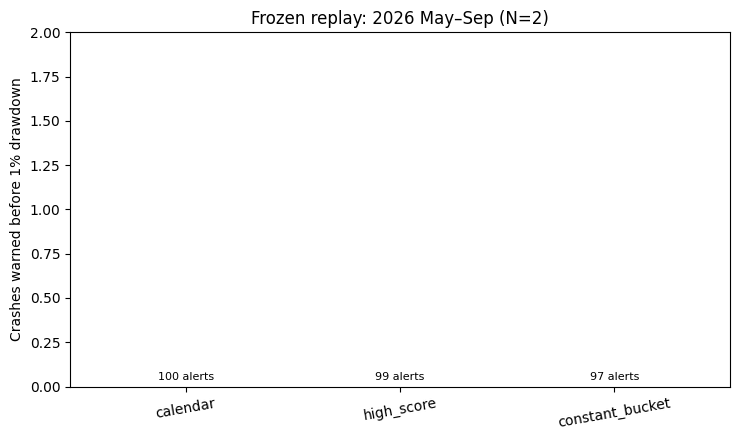

Complete. All output: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/FINAL_frozen_policy_May_Sep_2026_v2_source_verified
Three frozen policies; results reported as observed.


In [9]:
month_rows=[]
for name,a in test_alerts.items():
    ai=pd.to_datetime(a,utc=True)
    for mm in pd.date_range(START,END,freq='MS',inclusive='left'):
        sub=ai[(ai.year==mm.year)&(ai.month==mm.month)]
        month_rows.append({'policy':name,'month':mm.strftime('%Y-%m'),
            'alarms':len(sub),'last_alert_utc':sub.max().isoformat() if len(sub) else ''})
month_df=pd.DataFrame(month_rows)
month_df.to_csv(OUT/'FROZEN_monthly_burden.csv',index=False)
assert len(month_df)==15
# Preserve provenance; never infer a confidence interval from a single or tiny number of events.
report={
  'fixed_spec_sha256':sha,'study_status':'frozen policy later-period replay; NOT necessarily never-seen',
  'period_utc':'2026-05-01 through 2026-09-30','verified_market':SELECTED_VENUE, 'event_warmup_exclusion_minutes':240,
  'historic_reproduction':hist_summary,
  'n_new_price_events':len(NEW_EVENTS),
  'actual_policy_results':summary,
  'warnings':['Earlier project may have inspected through Sep 2026.',
              'No policy was fit or calibrated on the later-period outcomes.',
              'Calendar has 20/month; constant bucket has 20 burst and 240/year hard cap, with Jan-Apr state carried forward.',
              'Alert burden can differ across policies.'],
}
(OUT/'FROZEN_REPLAY_REPORT.json').write_text(json.dumps(report,indent=2,default=str))
fig,ax=plt.subplots(figsize=(7.5,4.5))
ax.bar(results.policy,results.caught_pre1pct)
for i,row in results.iterrows():ax.annotate(str(int(row.alerts_may_sep))+' alerts',
    (i,int(row.caught_pre1pct)),xytext=(0,5),textcoords='offset points',ha='center',fontsize=8)
ax.set_ylabel('Crashes warned before 1% drawdown')
ax.set_title(f'Frozen replay: 2026 May–Sep (N={len(NEW_EVENTS)})')
ax.set_ylim(0,max(1,int(results.caught_pre1pct.max())+2))
plt.xticks(rotation=10);plt.tight_layout()
fig.savefig(OUT/'FROZEN_early_warning_comparison.png',dpi=165)
plt.show()
print('Complete. All output:',OUT)
print('Three frozen policies; results reported as observed.')